In [ ]:
!pip -q install networkx lxml zstandard


In [ ]:
!pip -q install  pandas   rapidfuzz lxml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 18.0 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
# Put your .graphml somewhere in Drive and set the paths below.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ==== REQUIRED: set your pickle path ====
INPUT = "/content/drive/MyDrive/drug_kg_enriched.pkl"  # .pkl / .pkl.gz / .pkl.zst / .pkl.lz4

# Where to save tiny CSV samples
OUTDIR = "/content"
SAMPLE_N = 5  # how many rows to preview/save

# If your graph has explicit columns for these, set them here (or leave as None to auto-detect)
SECTION_NODE_COL = None   # e.g., "section", "sections", "partition"
SECTION_EDGE_COL = None   # e.g., "section", "edge_section"
NODE_TYPE_COL    = None   # e.g., "type", "label", "category", "node_type"
REL_COL          = None   # e.g., "relation", "type", "label", "predicate", "edge_type"


Loading: /content/drive/MyDrive/drug_kg_enriched.pkl
Loaded graph.
Directed: True | Multigraph: False
Nodes: 110851 | Edges: 103090

=== Nodes (sample head) ===


,id,name,type,source,section_type,description,source_db,retrieval_date
0,DRUG_GENERIC:3c84938e490d93b0,LIQUID FUNGAL NAIL TREATMENT,drug_generic,FDA_tool_list,,,,
1,DRUG_GENERIC:7d4dd2348577a4b6,"AVOBENZONE, HOMOSALATE, OCTISALATE, AND OCTOCR...",drug_generic,FDA_tool_list,,,,
2,DRUG_GENERIC:a3499718605b7f61,ACETAMINOPHEN,drug_generic,FDA_tool_list,,,,
3,DRUG_GENERIC:e2ba6f5a0560c3ef,STANNOUS FLUORIDE,drug_generic,FDA_tool_list,,,,
4,DRUG_GENERIC:45eee6be37fa6c0c,MECLIZINE HCL 25MG,drug_generic,FDA_tool_list,,,,



=== Edges (sample head) ===


,source,target,relation,weight,source_db,evidence,retrieval_date
0,DRUG_GENERIC:3c84938e490d93b0,SECTION:d574b31ffdd12014,HAS_ACTIVE_INGREDIENT_TEXT,,openfda_label_api,field:active_ingredient,2025-08-13
1,DRUG_GENERIC:3c84938e490d93b0,SECTION:ff6e343e4210fcbe,ASK_DOCTOR,,openfda_label_api,field:ask_doctor,2025-08-13
2,DRUG_GENERIC:3c84938e490d93b0,SECTION:a43f746bf6965b7c,DO_NOT_USE,,openfda_label_api,field:do_not_use,2025-08-13
3,DRUG_GENERIC:3c84938e490d93b0,SECTION:a682f3cdc231bd95,HAS_DOSAGE,,openfda_label_api,field:dosage_and_administration,2025-08-13
4,DRUG_GENERIC:3c84938e490d93b0,SECTION:170f85b492218055,HAS_INACTIVE_INGREDIENT_TEXT,,openfda_label_api,field:inactive_ingredient,2025-08-13



Relation column detected: relation

=== Relation counts (top 20) ===


,relation,count
0,BRAND_OF,34877
1,HAS_DOSAGE,9444
2,HAS_INDICATION_TEXT,9443
3,HAS_WARNING,7591
4,HAS_INACTIVE_INGREDIENT_TEXT,7108
5,HAS_ACTIVE_INGREDIENT_TEXT,7009
6,KEEP_OUT_OF_REACH,6986
7,HAS_PURPOSE,6872
8,STOP_USE,2814
9,HAS_STORAGE,2688


... (3 outputs left out)

,source_type,relation,target_type,count
0,drug_brand,BRAND_OF,drug_generic,34877
1,drug_generic,HAS_DOSAGE,section,9444
2,drug_generic,HAS_INDICATION_TEXT,section,9443
3,drug_generic,HAS_WARNING,section,7591
4,drug_generic,HAS_INACTIVE_INGREDIENT_TEXT,section,7108
5,drug_generic,HAS_ACTIVE_INGREDIENT_TEXT,section,7009
6,drug_generic,KEEP_OUT_OF_REACH,section,6986
7,drug_generic,HAS_PURPOSE,section,6872
8,drug_generic,STOP_USE,section,2814
9,drug_generic,HAS_STORAGE,section,2688



=== Degree stats ===
Top in-degree (id, deg): [('DRUG_GENERIC:52efcb6c3e9a3053', 1413), ('DRUG_GENERIC:19c128b2a3a439e2', 1173), ('DRUG_GENERIC:2bfe6d0f85108cc8', 856), ('DRUG_GENERIC:293e95c8a06eaa59', 759), ('DRUG_GENERIC:0ebc79111751865a', 586)]
Top out-degree (id, deg): [('DRUG_BRAND:05bcd0e7ceed08a1', 194), ('DRUG_BRAND:7955b936c48c9e75', 126), ('DRUG_BRAND:237b5017397b4de0', 65), ('DRUG_BRAND:6b8b7d71944e731e', 36), ('DRUG_BRAND:293e95c8a06eaa59', 27)]
In-degree — min: 0 max: 1413 mean: 0.9299870998006333
Out-degree — min: 0 max: 194 mean: 0.9299870998006333

=== Connectivity ===
Weakly connected components (top sizes): [28300, 452, 265, 252, 163]
Strongly connected components (top sizes): [1, 1, 1, 1, 1]
Density: 8.389599456929485e-06
Self-loops: 0

=== Edge 'weight' summary ===


,weight
count,103090
unique,2
top,
freq,68213



=== Charts ===


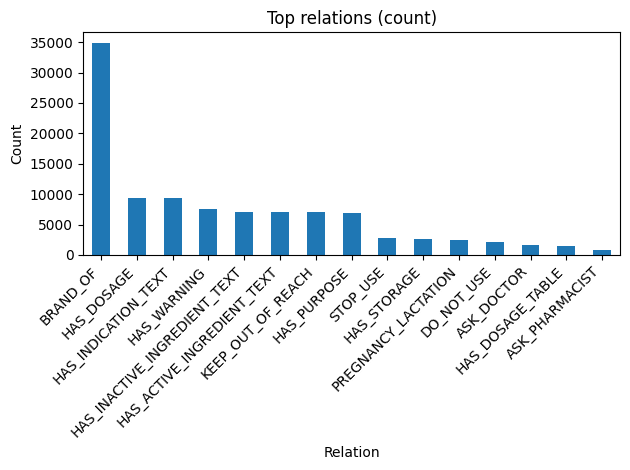


Saved tiny CSVs in: /content


In [ ]:
import os, io, pickle, gzip
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

def load_pickle_any(path):
    path_l = path.lower()
    if path_l.endswith(".pkl"):
        with open(path, "rb") as f: return pickle.load(f)
    elif path_l.endswith(".pkl.gz"):
        with gzip.open(path, "rb") as f: return pickle.load(f)
    elif path_l.endswith(".pkl.zst"):
        import zstandard as zstd
        with open(path, "rb") as f:
            d = zstd.ZstdDecompressor().decompress(f.read())
        return pickle.loads(d)
    elif path_l.endswith(".pkl.lz4"):
        import lz4.frame as lz4f
        with lz4f.open(path, "rb") as f: return pickle.load(f)
    else:
        # fallback: try normal pickle
        with open(path, "rb") as f: return pickle.load(f)

def ensure_graph(obj):
    # Accept a NetworkX graph or a dict that contains one
    if hasattr(obj, "nodes") and hasattr(obj, "edges"):
        return obj
    if isinstance(obj, dict):
        for k in ("G","graph","nx","nx_graph"):
            g = obj.get(k)
            if hasattr(g, "nodes") and hasattr(g, "edges"):
                return g
        # nodes/edges DataFrames?
        if "nodes" in obj and "edges" in obj and hasattr(nx, "from_pandas_edgelist"):
            nodes_df = obj["nodes"]
            edges_df = obj["edges"]
            src = detect_col(["source","src","u","from","id1"], edges_df.columns)
            dst = detect_col(["target","dst","v","to","id2"], edges_df.columns)
            G = nx.from_pandas_edgelist(edges_df, source=src, target=dst, edge_attr=True, create_using=nx.Graph())
            # set node attrs if nodes_df has id
            nid = detect_col(["id","node","name"], nodes_df.columns)
            if nid:
                nx.set_node_attributes(G, nodes_df.set_index(nid).to_dict(orient="index"))
            return G
    raise TypeError("Pickle did not contain a NetworkX graph or recognizable structure.")

def detect_col(candidates, cols):
    cols_lower = {c.lower(): c for c in cols}
    for cand in candidates:
        if cand.lower() in cols_lower:
            return cols_lower[cand.lower()]
    return None

def graph_to_frames(G, sample_n=5, node_type_hint=None, rel_hint=None):
    # Nodes → DataFrame
    node_rows = []
    for nid, attrs in list(G.nodes(data=True))[:sample_n]:
        row = {"id": nid}
        row.update(attrs)
        node_rows.append(row)
    nodes_df = pd.DataFrame(node_rows)

    # Edges → DataFrame
    if G.is_multigraph():
        edge_iter = list(G.edges(keys=True, data=True))[:sample_n]
        edge_rows = []
        for u,v,k,attrs in edge_iter:
            row = {"source": u, "target": v, "key": k}
            row.update(attrs)
            edge_rows.append(row)
    else:
        edge_iter = list(G.edges(data=True))[:sample_n]
        edge_rows = []
        for u,v,attrs in edge_iter:
            row = {"source": u, "target": v}
            row.update(attrs)
            edge_rows.append(row)
    edges_df = pd.DataFrame(edge_rows)

    # Detect columns
    node_type_col = node_type_hint or detect_col(["type","label","category","node_type","kind"], list(nodes_df.columns) if not nodes_df.empty else [])
    rel_col = rel_hint
    if rel_col is None and not edges_df.empty:
        rel_col = detect_col(["relation","rel","type","label","predicate","edge_type","relation_type","relationship"], edges_df.columns)

    return nodes_df, edges_df, node_type_col, rel_col

def full_edges_frame(G):
    # Build a thin edges DF for counting/grouping (not just sample)
    # This avoids holding all attrs if memory is tight.
    rows = []
    if G.is_multigraph():
        for u,v,k,d in G.edges(keys=True, data=True):
            rows.append((u,v,k,d))
    else:
        for u,v,d in G.edges(data=True):
            rows.append((u,v,None,d))
    return rows

def add_endpoint_types(G, edges_df, node_type_col):
    if node_type_col is None:
        return edges_df
    # build a small map of id -> type
    map_type = {}
    for n, d in G.nodes(data=True):
        t = d.get(node_type_col)
        map_type[n] = t
    edges_df["source_type"] = edges_df["source"].map(map_type)
    edges_df["target_type"] = edges_df["target"].map(map_type)
    return edges_df

def series_top(s, n=20):
    return s.value_counts(dropna=False).head(n).rename_axis(s.name or "value").reset_index(name="count")

print("Loading:", INPUT)
obj = load_pickle_any(INPUT)
G = ensure_graph(obj)
print("Loaded graph.")
print("Directed:", G.is_directed(), "| Multigraph:", G.is_multigraph())
print("Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges())

# --- Samples
nodes_df, edges_df, detected_node_type_col, detected_rel_col = graph_to_frames(
    G, sample_n=SAMPLE_N, node_type_hint=NODE_TYPE_COL, rel_hint=REL_COL
)

# --- Choose section/type/rel columns (auto unless overridden)
node_cols_all = set()
for _, d in list(G.nodes(data=True))[:50]:
    node_cols_all |= set(d.keys())
edge_cols_all = set()
ei = G.edges(keys=True, data=True) if G.is_multigraph() else G.edges(data=True)
for i, e in enumerate(ei):
    edge_cols_all |= set(e[-1].keys())
    if i >= 49: break

node_section_col = SECTION_NODE_COL or detect_col(["section","sections","partition","segment","group","bucket"], node_cols_all)
edge_section_col = SECTION_EDGE_COL or detect_col(["section","sections","edge_section","partition","segment","group"], edge_cols_all)

# --- Build thin full edges DF for grouping
rows = full_edges_frame(G)
import pandas as pd
if rows:
    ecols = ["source","target","key","_attrs"]
    all_edges_df = pd.DataFrame(rows, columns=ecols)
    # pull relation column if it exists
    rel_col = REL_COL or detected_rel_col
    if rel_col is not None:
        all_edges_df[rel_col] = all_edges_df["_attrs"].map(lambda d: d.get(rel_col))
    # pull section if exists
    if edge_section_col is not None:
        all_edges_df[edge_section_col] = all_edges_df["_attrs"].map(lambda d: d.get(edge_section_col))
else:
    all_edges_df = pd.DataFrame(columns=["source","target","key","_attrs"])

# --- Nodes thin DF for grouping by type/section
node_rows = [{"id": n, **d} for n, d in G.nodes(data=True)]
all_nodes_df = pd.DataFrame(node_rows) if node_rows else pd.DataFrame(columns=["id"])

# --- Display samples
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

print("\n=== Nodes (sample head) ===")
display(nodes_df if not nodes_df.empty else pd.DataFrame({"info":["<no node attributes in sample>"]}))

print("\n=== Edges (sample head) ===")
display(edges_df if not edges_df.empty else pd.DataFrame({"info":["<no edge attributes in sample>"]}))

# --- Relation counts
rel_col = REL_COL or detected_rel_col
print("\nRelation column detected:", rel_col)
if rel_col and not all_edges_df.empty and rel_col in all_edges_df.columns:
    rel_top = series_top(all_edges_df[rel_col], 20)
    print("\n=== Relation counts (top 20) ===")
    display(rel_top)
else:
    print("No obvious relation column on edges (set REL_COL to force).")

# --- Section-wise counts
print("\nNode section column detected:", node_section_col)
if node_section_col and not all_nodes_df.empty and node_section_col in all_nodes_df.columns:
    node_sec_top = series_top(all_nodes_df[node_section_col], 20)
    print("\n=== Node counts by section (top 20) ===")
    display(node_sec_top)
else:
    print("No node section column found (set SECTION_NODE_COL to force).")

print("\nEdge section column detected:", edge_section_col)
if edge_section_col and not all_edges_df.empty and edge_section_col in all_edges_df.columns:
    edge_sec_top = series_top(all_edges_df[edge_section_col], 20)
    print("\n=== Edge counts by section (top 20) ===")
    display(edge_sec_top)
else:
    print("No edge section column found (set SECTION_EDGE_COL to force).")

# --- Node type counts
node_type_col = NODE_TYPE_COL or detected_node_type_col
print("\nNode type column detected:", node_type_col)
if node_type_col and not all_nodes_df.empty and node_type_col in all_nodes_df.columns:
    node_type_top = series_top(all_nodes_df[node_type_col], 20)
    print("\n=== Node counts by type (top 20) ===")
    display(node_type_top)
else:
    print("No node type column found (set NODE_TYPE_COL to force).")

# --- Edge schema preview: (source_type, relation, target_type)
if node_type_col and rel_col and not all_edges_df.empty:
    # attach endpoint types
    thin = all_edges_df[["source","target", rel_col]].copy()
    # map endpoint types
    node_type_map = {}
    if not all_nodes_df.empty and "id" in all_nodes_df.columns and node_type_col in all_nodes_df.columns:
        node_type_map = dict(zip(all_nodes_df["id"], all_nodes_df[node_type_col]))
    thin["source_type"] = thin["source"].map(node_type_map)
    thin["target_type"] = thin["target"].map(node_type_map)
    trip = thin.groupby(["source_type", rel_col, "target_type"]).size().sort_values(ascending=False).head(20).reset_index(name="count")
    print("\n=== Edge schema (top 20) — (source_type, relation, target_type) ===")
    display(trip)

# --- Degree stats
print("\n=== Degree stats ===")
if G.is_directed():
    indeg = sorted(G.in_degree, key=lambda x: x[1], reverse=True)[:10]
    outdeg = sorted(G.out_degree, key=lambda x: x[1], reverse=True)[:10]
    print("Top in-degree (id, deg):", indeg[:5])
    print("Top out-degree (id, deg):", outdeg[:5])
else:
    deg = sorted(G.degree, key=lambda x: x[1], reverse=True)[:10]
    print("Top degree (id, deg):", deg[:5])

# quick numeric stats
import numpy as np
if not G.is_directed():
    deg_vals = np.fromiter((d for _, d in G.degree()), dtype=np.int64, count=G.number_of_nodes())
    if len(deg_vals):
        print("Degree — min:", int(deg_vals.min()), "max:", int(deg_vals.max()),
              "mean:", float(deg_vals.mean()), "median:", float(np.median(deg_vals)))
else:
    indeg_vals = np.fromiter((d for _, d in G.in_degree()), dtype=np.int64, count=G.number_of_nodes())
    outdeg_vals = np.fromiter((d for _, d in G.out_degree()), dtype=np.int64, count=G.number_of_nodes())
    if len(indeg_vals):
        print("In-degree — min:", int(indeg_vals.min()), "max:", int(indeg_vals.max()),
              "mean:", float(indeg_vals.mean()))
    if len(outdeg_vals):
        print("Out-degree — min:", int(outdeg_vals.min()), "max:", int(outdeg_vals.max()),
              "mean:", float(outdeg_vals.mean()))

# --- Components / connectivity
print("\n=== Connectivity ===")
try:
    if G.is_directed():
        wcc_sizes = sorted((len(c) for c in nx.weakly_connected_components(G)), reverse=True)[:5]
        scc_sizes = sorted((len(c) for c in nx.strongly_connected_components(G)), reverse=True)[:5]
        print("Weakly connected components (top sizes):", wcc_sizes[:5])
        print("Strongly connected components (top sizes):", scc_sizes[:5])
    else:
        cc_sizes = sorted((len(c) for c in nx.connected_components(G)), reverse=True)[:5]
        print("Connected components (top sizes):", cc_sizes[:5])
except Exception as e:
    print("Component stats skipped:", e)

# --- Density / clustering / self-loops
try:
    print("Density:", nx.density(G))
except Exception as e:
    print("Density not available:", e)

try:
    if not G.is_directed() and not G.is_multigraph():
        print("Average clustering:", nx.average_clustering(G))
        print("Transitivity:", nx.transitivity(G))
except Exception as e:
    print("Clustering skipped:", e)

try:
    print("Self-loops:", nx.number_of_selfloops(G))
except Exception as e:
    print("Self-loop check skipped:", e)

# --- Edge weight quick summary (if present)
wcol = detect_col(["weight","Weight","score","cost"], edge_cols_all)
if wcol:
    # collect quickly; avoid building full df if huge
    weights = []
    ei = G.edges(data=True) if not G.is_multigraph() else G.edges(keys=True, data=True)
    for e in ei:
        d = e[-1]
        if wcol in d: weights.append(d[wcol])
    if weights:
        s = pd.Series(weights, name=wcol)
        print(f"\n=== Edge '{wcol}' summary ===")
        display(s.describe())

# --- Optional: charts (separate figures, no custom colors)
print("\n=== Charts ===")
try:
    if not G.is_directed():
        import numpy as np
        deg_vals = [d for _, d in G.degree()]
        plt.figure()
        plt.hist(deg_vals, bins=50)
        plt.title("Degree distribution")
        plt.xlabel("Degree")
        plt.ylabel("Frequency")
        plt.show()
    if rel_col and not all_edges_df.empty and rel_col in all_edges_df.columns:
        rel_counts = all_edges_df[rel_col].value_counts().head(20)
        plt.figure()
        rel_counts.plot(kind="bar")
        plt.title("Top relations (count)")
        plt.xlabel("Relation")
        plt.ylabel("Count")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()
except Exception as e:
    print("Charting skipped:", e)

# --- Save samples (tiny CSVs)
os.makedirs(OUTDIR, exist_ok=True)
if not nodes_df.empty:
    nodes_df.to_csv(os.path.join(OUTDIR, "nodes_sample.csv"), index=False)
if not edges_df.empty:
    edges_df.to_csv(os.path.join(OUTDIR, "edges_sample.csv"), index=False)
if rel_col and not all_edges_df.empty and rel_col in all_edges_df.columns:
    series_top(all_edges_df[rel_col], 100).to_csv(os.path.join(OUTDIR, "relation_counts_top100.csv"), index=False)

print("\nSaved tiny CSVs in:", OUTDIR)


In [ ]:
# ---- REQUIRED: set your pickle path ----
PICKLE_PATH = "/content/drive/MyDrive/drug_kg_enriched.pkl"  # .pkl / .pkl.gz / .pkl.zst / .pkl.lz4

# Query:
DRUG_QUERY = "atorvastatin"     # ⬅️ change this (brand or generic)

# Output folder for tiny CSVs:
OUTDIR = "/content"

# Hints (leave as None to auto-detect)
NODE_TYPE_COL = None            # e.g. "type", "label", "category", "node_type"
REL_COL       = None            # e.g. "relation", "type", "label", "predicate", "edge_type"
NODE_SECTION_COL = None         # e.g. "section", "sections", "partition"
EDGE_SECTION_COL = None         # e.g. "section", "edge_section", "partition"

# Name fields to try on nodes (ordered by priority)
NAME_COLUMNS = ["name", "preferred_name", "label", "drug_name", "generic_name", "brand_name", "title"]

# If your nodes store synonyms, add likely fields here:
SYN_COLUMNS = ["synonyms", "alias", "aliases", "aka", "syns"]


In [ ]:
import os, pickle, gzip, re, unicodedata
import pandas as pd
import networkx as nx
from rapidfuzz import fuzz, process

def load_pickle_any(path):
    pl = path.lower()
    if pl.endswith(".pkl"):
        with open(path, "rb") as f: return pickle.load(f)
    if pl.endswith(".pkl.gz"):
        with gzip.open(path, "rb") as f: return pickle.load(f)
    if pl.endswith(".pkl.zst"):
        import zstandard as zstd
        with open(path, "rb") as f:
            d = zstd.ZstdDecompressor().decompress(f.read())
        return pickle.loads(d)
    if pl.endswith(".pkl.lz4"):
        import lz4.frame as lz4f
        with lz4f.open(path, "rb") as f: return pickle.load(f)
    with open(path, "rb") as f: return pickle.load(f)

def detect_col(candidates, cols):
    cols_l = {c.lower(): c for c in cols}
    for cand in candidates:
        if cand.lower() in cols_l: return cols_l[cand.lower()]
    return None

def normalize_text(s):
    if s is None: return None
    if not isinstance(s, str): s = str(s)
    s = unicodedata.normalize("NFKD", s).encode("ascii","ignore").decode("ascii")
    s = s.lower().strip()
    s = re.sub(r"[\s\-_]+", " ", s)
    s = re.sub(r"[^\w\s\.\+]", "", s)  # keep alnum, spaces, dot, plus (for salts)
    return s

def iter_name_like(values):
    """Yield string tokens from a value or list/str of synonyms."""
    if values is None: return
    if isinstance(values, (list, tuple, set)):
        for v in values:
            vs = normalize_text(v)
            if vs: yield vs
    elif isinstance(values, str):
        # split on common separators if it looks like a packed synonyms string
        if ";" in values or "|" in values or "," in values:
            for v in re.split(r"[;|,]", values):
                vs = normalize_text(v)
                if vs: yield vs
        else:
            vs = normalize_text(values)
            if vs: yield vs

def collect_node_strings(nid, attrs, name_cols, syn_cols):
    # preferred names
    strings = []
    for c in name_cols:
        if c in attrs:
            strings.extend(list(iter_name_like(attrs[c])))
    # synonyms
    for c in syn_cols:
        if c in attrs:
            strings.extend(list(iter_name_like(attrs[c])))
    # include the id itself if it's readable
    strings.extend(list(iter_name_like(nid)))
    # unique while preserving order
    seen = set()
    out = []
    for s in strings:
        if s and s not in seen:
            seen.add(s); out.append(s)
    return out

def detect_schema(G, sample_nodes=100, sample_edges=200):
    # node keys
    node_keys = set()
    for i, (_, d) in enumerate(G.nodes(data=True)):
        node_keys |= set(d.keys())
        if i >= sample_nodes: break

    # edge keys
    edge_keys = set()
    ei = G.edges(keys=True, data=True) if G.is_multigraph() else G.edges(data=True)
    for i, e in enumerate(ei):
        edge_keys |= set(e[-1].keys())
        if i >= sample_edges: break

    node_type = NODE_TYPE_COL or detect_col(["type","label","category","node_type","kind"], node_keys)
    rel_col   = REL_COL or detect_col(["relation","rel","type","label","predicate","edge_type","relation_type","relationship"], edge_keys)
    node_sec  = NODE_SECTION_COL or detect_col(["section","sections","partition","segment","group","bucket"], node_keys)
    edge_sec  = EDGE_SECTION_COL or detect_col(["section","sections","edge_section","partition","segment","group"], edge_keys)
    return node_type, rel_col, node_sec, edge_sec, node_keys, edge_keys

def find_drug_candidates(G, query, node_type_col, name_cols, syn_cols, prefer_type={"drug","Drug","DRUG"}):
    qn = normalize_text(query)
    if not qn: return []

    # Scan all nodes once; collect plausible candidates with scores
    cands = []
    for nid, attrs in G.nodes(data=True):
        strings = collect_node_strings(nid, attrs, name_cols, syn_cols)
        if not strings: continue
        # quick exact/substring check
        exact = qn in strings
        substr = any(qn in s for s in strings)
        # fuzzy ratio on best string
        best_str = process.extractOne(qn, strings, scorer=fuzz.WRatio)
        score = best_str[1] if best_str else 0
        tval = (attrs.get(node_type_col) if node_type_col else None)
        is_drugish = (str(tval) in prefer_type) if tval is not None else False

        # relevance heuristics
        bonus = 0
        if exact: bonus += 30
        if substr: bonus += 10
        if is_drugish: bonus += 15
        rank = score + bonus

        if exact or substr or score >= 70:   # keep good fuzzy hits
            cands.append({
                "node_id": nid,
                "rank": rank,
                "score": score,
                "is_drugish": is_drugish,
                "best_match": best_str[0] if best_str else None,
                "type": tval,
                "name_preview": next((s for s in strings if s), None)
            })
    # sort by our combined rank, then by fuzzy score
    cands.sort(key=lambda r: (r["is_drugish"], r["rank"], r["score"]), reverse=True)
    return cands

def edges_touching_node(G, nid):
    rows = []
    if G.is_multigraph():
        for u, v, k, d in G.edges(nid, keys=True, data=True):
            other = v if u == nid else u
            rows.append((u, v, k, other, d))
    else:
        for u, v, d in G.edges(nid, data=True):
            other = v if u == nid else u
            rows.append((u, v, None, other, d))
    return rows

def display_df(df, name):
    print(f"\n=== {name} ===")
    if df is None or df.empty:
        print("<empty>")
    else:
        display(df.head(10))

# ----------------- Run -----------------
print("Loading graph:", PICKLE_PATH)
obj = load_pickle_any(PICKLE_PATH)
G = obj if hasattr(obj, "nodes") else obj.get("G", obj.get("graph", obj))
if not hasattr(G, "nodes"):
    raise TypeError("Pickle did not contain a NetworkX graph.")
print("Loaded. Directed:", G.is_directed(), "| Multigraph:", G.is_multigraph())
print("Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges())

node_type_col, rel_col, node_sec_col, edge_sec_col, node_keys, edge_keys = detect_schema(G)
print("Detected columns →",
      "node_type:", node_type_col, "| rel:", rel_col,
      "| node_section:", node_sec_col, "| edge_section:", edge_sec_col)

# ---- Find drug by name ----
cands = find_drug_candidates(G, DRUG_QUERY, node_type_col, NAME_COLUMNS, SYN_COLUMNS)
cand_df = pd.DataFrame(cands)[["node_id","type","best_match","score","rank","is_drugish"]].head(20)
display_df(cand_df, f"Candidates for '{DRUG_QUERY}' (top 20)")

if not cands:
    raise SystemExit("No candidates found. Try a different spelling or add to NAME_COLUMNS/SYN_COLUMNS hints.")

chosen = cands[0]["node_id"]
print("Chosen node_id:", chosen, "| type:", G.nodes[chosen].get(node_type_col))

# ---- Show node attributes ----
attr_items = sorted(G.nodes[chosen].items(), key=lambda x: x[0].lower())
node_attr_df = pd.DataFrame(attr_items, columns=["attribute","value"])
display_df(node_attr_df, "Chosen node — attributes")

# ---- Collect edges touching the drug ----
rows = edges_touching_node(G, chosen)
if not rows:
    raise SystemExit("No edges found for this node.")

# Build a compact edges DF
records = []
for u, v, k, other, d in rows:
    rec = {"source": u, "target": v, "neighbor": other}
    if k is not None: rec["key"] = k
    if rel_col and rel_col in d: rec["relation"] = d.get(rel_col)
    if edge_sec_col and edge_sec_col in d: rec["edge_section"] = d.get(edge_sec_col)
    # capture common weight-ish columns if present
    for wc in ("weight","score","strength","confidence","prob","p_value"):
        if wc in d: rec[wc] = d[wc]
    records.append(rec)

edges_df = pd.DataFrame.from_records(records)
display_df(edges_df, "Edges touching chosen node (sample)")

# ---- Neighbor type & names (if available)
# Build a id->type/name map for fast lookup
name_col_detect = detect_col(NAME_COLUMNS, node_keys) or "name"
node_type_map = {n: G.nodes[n].get(node_type_col) for n in G.nodes()} if node_type_col else {}
node_name_map = {n: G.nodes[n].get(name_col_detect, n) for n in G.nodes()}

edges_df["neighbor_type"] = edges_df["neighbor"].map(node_type_map) if node_type_col else None
edges_df["neighbor_name"] = edges_df["neighbor"].map(node_name_map)

# ---- Summaries
def series_top(s, n=20):
    return s.value_counts(dropna=False).head(n).rename_axis(s.name or "value").reset_index(name="count")

print("\n=== Counts ===")
print("Total edges touching drug:", len(edges_df))

if "relation" in edges_df.columns:
    display_df(series_top(edges_df["relation"], 30), "Relation counts (top 30)")

if "neighbor_type" in edges_df.columns:
    display_df(series_top(edges_df["neighbor_type"], 30), "Neighbor type counts (top 30)")

if "edge_section" in edges_df.columns:
    display_df(series_top(edges_df["edge_section"], 30), "Edge section counts (top 30)")

# Show top neighbors by degree within this ego-graph
top_neighbors = edges_df["neighbor"].value_counts().head(20).reset_index()
top_neighbors.columns = ["neighbor","edge_count_with_drug"]
top_neighbors["neighbor_name"] = top_neighbors["neighbor"].map(node_name_map)
top_neighbors["neighbor_type"] = top_neighbors["neighbor"].map(node_type_map) if node_type_col else None
display_df(top_neighbors, "Top neighbors (by # of edges with this drug)")

# If we have a weight-ish column, show top by it
weight_cols_present = [c for c in ("score","weight","strength","confidence","prob") if c in edges_df.columns]
if weight_cols_present:
    wc = weight_cols_present[0]
    top_by_w = edges_df.sort_values(wc, ascending=False).head(20)[["neighbor","neighbor_name","neighbor_type","relation", wc]]
    display_df(top_by_w, f"Top neighbors by '{wc}'")

# ---- Section-wise node counts (if node section exists)
if node_sec_col:
    # extract sections for the chosen node and its neighbors (unique)
    chosen_sec = G.nodes[chosen].get(node_sec_col, None)
    print("\nChosen node section:", chosen_sec)
    # neighbor sections distribution
    nsecs = []
    for nid in set(edges_df["neighbor"]):
        nsecs.append(G.nodes[nid].get(node_sec_col, None))
    nsec_df = series_top(pd.Series(nsecs, name=node_sec_col), 30)
    display_df(nsec_df, "Neighbor node counts by section (top 30)")

# ---- CSV exports (tiny)
os.makedirs(OUTDIR, exist_ok=True)
cand_path = os.path.join(OUTDIR, "drug_query_candidates.csv")
edges_path = os.path.join(OUTDIR, "drug_edges_sample.csv")
node_attr_path = os.path.join(OUTDIR, "drug_node_attributes.csv")
pd.DataFrame(cands).to_csv(cand_path, index=False)
edges_df.head(1000).to_csv(edges_path, index=False)
node_attr_df.to_csv(node_attr_path, index=False)
print("\nSaved:", cand_path, "|", edges_path, "|", node_attr_path)


Loading graph: /content/drive/MyDrive/drug_kg_enriched.pkl
Loaded. Directed: True | Multigraph: False
Nodes: 110851 | Edges: 103090
Detected columns → node_type: type | rel: relation | node_section: None | edge_section: None

=== Candidates for 'atorvastatin' (top 20) ===


,node_id,type,best_match,score,rank,is_drugish
0,DRUG_GENERIC:bd1e31d76876b972,drug_generic,atorvastatin film coated,90.0,100.0,False
1,DRUG_GENERIC:e9162b4ab73fae90,drug_generic,atorvastatin calcium,90.0,100.0,False
2,DRUG_GENERIC:ac63221f15faa3de,drug_generic,ezetimibe and atorvastatin,90.0,100.0,False
3,DRUG_GENERIC:f53d54ea483ee61c,drug_generic,amlodipine besylate and atorvastatin calcium,90.0,100.0,False
4,DRUG_GENERIC:fe29eb33ab0a5a1f,drug_generic,atorvastatin calcium,90.0,100.0,False
5,DRUG_GENERIC:44e42389af0743f4,drug_generic,atorvastatin calcium,90.0,100.0,False
6,DRUG_BRAND:44e42389af0743f4,drug_brand,atorvastatin calcium,90.0,100.0,False
7,SECTION:892ca0377fa80e52,section,dosage and administration amlodipine besylate ...,90.0,100.0,False
8,SECTION:16c1d9256cb6ba09,section,dosage and administration table amlodipine bes...,90.0,100.0,False
9,SECTION:a8adaed58c669060,section,indications and usage amlodipine besylate and ...,90.0,100.0,False


Chosen node_id: DRUG_GENERIC:bd1e31d76876b972 | type: drug_generic

=== Chosen node — attributes ===


,attribute,value
0,description,
1,id,DRUG_GENERIC:bd1e31d76876b972
2,name,ATORVASTATIN FILM COATED
3,retrieval_date,
4,section_type,
5,source,FDA_tool_list
6,source_db,
7,type,drug_generic



=== Edges touching chosen node (sample) ===


,source,target,neighbor,relation,weight
0,DRUG_GENERIC:bd1e31d76876b972,SECTION:a9427361122c03c5,SECTION:a9427361122c03c5,HAS_DOSAGE,
1,DRUG_GENERIC:bd1e31d76876b972,SECTION:03162fc5e7e43f4b,SECTION:03162fc5e7e43f4b,HAS_INDICATION_TEXT,


... (5 outputs left out)

,neighbor,edge_count_with_drug,neighbor_name,neighbor_type
0,SECTION:a9427361122c03c5,1,dosage_and_administration (ATORVASTATIN FILM C...,section
1,SECTION:03162fc5e7e43f4b,1,indications_and_usage (ATORVASTATIN FILM COATED),section



=== Top neighbors by 'weight' ===


,neighbor,neighbor_name,neighbor_type,relation,weight
0,SECTION:a9427361122c03c5,dosage_and_administration (ATORVASTATIN FILM C...,section,HAS_DOSAGE,
1,SECTION:03162fc5e7e43f4b,indications_and_usage (ATORVASTATIN FILM COATED),section,HAS_INDICATION_TEXT,



Saved: /content/drug_query_candidates.csv | /content/drug_edges_sample.csv | /content/drug_node_attributes.csv


In [ ]:
# === Single Cell: Drug-centric plots & EDA from a pickled NetworkX graph ===
# Set these two and run the cell.
PICKLE_PATH = "/content/drive/MyDrive/drug_kg_enriched.pkl"    # .pkl / .pkl.gz / .pkl.zst / .pkl.lz4
DRUG_QUERY  = "atorvastatin"                                        # brand or generic

# Optional: force your column names here (else auto-detect)
NODE_TYPE_COL     = None    # e.g., "type", "label", "category", "node_type"
REL_COL           = None    # e.g., "relation", "type", "label", "predicate", "edge_type"
NODE_SECTION_COL  = None    # e.g., "section", "sections", "partition"
EDGE_SECTION_COL  = None    # e.g., "section", "edge_section", "partition"

# Ego graph & plotting controls
EGO_RADIUS     = 1          # try 2 if 1-hop has few edges
MAX_EGO_NODES  = 250        # cap for readability
LABEL_TOP_N    = 25         # label center + top-degree nodes
SEED_LAYOUT    = 42         # spring layout seed
EDGE_WEIGHT_PREF = ["score","weight","strength","confidence","prob"]  # for edge width scaling

# --------------------------------------------------------------------------------
# Install deps (Colab-friendly) and imports
# --------------------------------------------------------------------------------
import sys, subprocess, math, re, gzip, pickle, unicodedata, os
for pkg in ["networkx","pandas","matplotlib","zstandard","lz4","rapidfuzz","lxml"]:
    try:
        __import__(pkg if pkg != "zstandard" else "zstandard")
    except:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from rapidfuzz import fuzz, process
from IPython.display import display

plt.rcParams["figure.dpi"] = 120

# --------------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------------
def load_pickle_any(path):
    pl = path.lower()
    if pl.endswith(".pkl"):
        with open(path, "rb") as f: return pickle.load(f)
    if pl.endswith(".pkl.gz"):
        with gzip.open(path, "rb") as f: return pickle.load(f)
    if pl.endswith(".pkl.zst"):
        import zstandard as zstd
        with open(path, "rb") as f: d = zstd.ZstdDecompressor().decompress(f.read())
        return pickle.loads(d)
    if pl.endswith(".pkl.lz4"):
        import lz4.frame as lz4f
        with lz4f.open(path, "rb") as f: return pickle.load(f)
    with open(path, "rb") as f: return pickle.load(f)

def detect_col(cands, cols):
    cols_l = {c.lower(): c for c in cols}
    for c in cands:
        if c.lower() in cols_l: return cols_l[c.lower()]
    return None

def normalize_text(s):
    if s is None: return None
    if not isinstance(s, str): s = str(s)
    s = unicodedata.normalize("NFKD", s).encode("ascii","ignore").decode("ascii")
    s = s.lower().strip()
    s = re.sub(r"[\s\-_]+", " ", s)
    s = re.sub(r"[^\w\s\.\+]", "", s)
    return s

def detect_schema(G, sample_nodes=200, sample_edges=400):
    node_keys, edge_keys = set(), set()
    for i, (_, d) in enumerate(G.nodes(data=True)):
        node_keys |= set(d.keys())
        if i >= sample_nodes: break
    ei = G.edges(keys=True, data=True) if G.is_multigraph() else G.edges(data=True)
    for i, e in enumerate(ei):
        edge_keys |= set(e[-1].keys())
        if i >= sample_edges: break
    node_type = NODE_TYPE_COL or detect_col(["type","label","category","node_type","kind"], node_keys)
    rel_col   = REL_COL or detect_col(["relation","rel","type","label","predicate","edge_type","relation_type","relationship"], edge_keys)
    node_sec  = NODE_SECTION_COL or detect_col(["section","sections","partition","segment","group","bucket"], node_keys)
    edge_sec  = EDGE_SECTION_COL or detect_col(["section","sections","edge_section","partition","segment","group"], edge_keys)
    return node_type, rel_col, node_sec, edge_sec

def find_drug_node(G, query, node_type_col=None, prefer_type={"drug","Drug","DRUG"}):
    qn = normalize_text(query)
    if not qn: return None
    name_cols = ["name","preferred_name","label","drug_name","generic_name","brand_name","title"]
    syn_cols  = ["synonyms","alias","aliases","aka","syns"]
    cands = []
    for nid, attrs in G.nodes(data=True):
        strings = []
        for c in name_cols:
            if c in attrs:
                v = attrs[c]
                if isinstance(v, (list,tuple,set)):
                    strings.extend([normalize_text(x) for x in v if normalize_text(x)])
                else:
                    strings.append(normalize_text(v))
        for c in syn_cols:
            if c in attrs:
                v = attrs[c]
                if isinstance(v, (list,tuple,set)):
                    strings.extend([normalize_text(x) for x in v if normalize_text(x)])
                elif isinstance(v, str):
                    if ";" in v or "|" in v or "," in v:
                        for x in re.split(r"[;|,]", v):
                            nv = normalize_text(x)
                            if nv: strings.append(nv)
                    else:
                        strings.append(normalize_text(v))
        strings.append(normalize_text(nid))
        strings = [s for s in strings if s]
        if not strings: continue
        exact  = qn in strings
        substr = any(qn in s for s in strings)
        best   = process.extractOne(qn, strings, scorer=fuzz.WRatio)
        score  = best[1] if best else 0
        tval   = (attrs.get(node_type_col) if node_type_col else None)
        is_drugish = (str(tval) in prefer_type) if tval is not None else False
        bonus = (30 if exact else 0) + (10 if substr else 0) + (15 if is_drugish else 0)
        rank  = score + bonus
        if exact or substr or score >= 70:
            cands.append((rank, score, is_drugish, nid))
    if not cands:
        return None
    cands.sort(reverse=True)
    return cands[0][3]

def pick_weight_col(edge_attr_sample, pref_list):
    for c in pref_list:
        if c in edge_attr_sample: return c
    for k,v in edge_attr_sample.items():
        if isinstance(v,(int,float)): return k
    return None

def safe_bar(series, title, xlabel, topn=20):
    series = series.dropna()
    if series.empty:
        print(f"[skip] {title} — no data to plot.")
        return
    plt.figure()
    series.head(topn).plot(kind="bar")
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

def pick_attr_key_from_attrs(dict_series, candidates):
    keys_present = set()
    for d in dict_series:
        if isinstance(d, dict):
            keys_present |= set(d.keys())
    for k in candidates:
        if k in keys_present:
            vals = [d.get(k) for d in dict_series if isinstance(d, dict)]
            if any(v is not None and v != "" for v in vals):
                return k
    return None

# --------------------------------------------------------------------------------
# Load graph
# --------------------------------------------------------------------------------
print("Loading graph:", PICKLE_PATH)
obj = load_pickle_any(PICKLE_PATH)
G = obj if hasattr(obj, "nodes") else obj.get("G", obj.get("graph", obj))
if not hasattr(G, "nodes"):
    raise TypeError("Pickle did not contain a NetworkX graph.")
print("Loaded. Directed:", G.is_directed(), "| Multigraph:", G.is_multigraph(),
      "| Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges())

node_type_col, rel_col, node_sec_col, edge_sec_col = detect_schema(G)
print("Detected → node_type:", node_type_col, "| relation:", rel_col,
      "| node_section:", node_sec_col, "| edge_section:", edge_sec_col)

# --------------------------------------------------------------------------------
# Find drug node
# --------------------------------------------------------------------------------
drug_nid = find_drug_node(G, DRUG_QUERY, node_type_col=node_type_col)
if drug_nid is None:
    raise SystemExit(f"No matching node found for '{DRUG_QUERY}'. Try a different spelling or set schema hints.")
print("Chosen drug node_id:", drug_nid, "| type:", G.nodes[drug_nid].get(node_type_col))

# Show node attributes (head)
node_attr_df = pd.DataFrame(sorted(G.nodes[drug_nid].items(), key=lambda x: x[0].lower()),
                            columns=["attribute","value"])
print("\n=== Chosen node — attributes (head) ===")
display(node_attr_df.head(20))

# --------------------------------------------------------------------------------
# Build ego-subgraph (auto-widen to radius 2 if radius 1 is empty)
# --------------------------------------------------------------------------------
def build_ego(G, center, r):
    try:
        nodes = nx.ego_graph(G, center, radius=r, undirected=not G.is_directed()).nodes()
        nodes = set(nodes)
        if len(nodes) > MAX_EGO_NODES:
            degs = dict(G.degree(nodes))
            keep = {center}
            keep.update([n for n,_ in sorted(degs.items(), key=lambda x: x[1], reverse=True)[:MAX_EGO_NODES-1]])
            nodes = keep
        return G.subgraph(nodes).copy()
    except Exception as e:
        print("Ego build failed:", e)
        return nx.empty_graph()

E = build_ego(G, drug_nid, EGO_RADIUS)
if E.number_of_edges() == 0 and EGO_RADIUS == 1:
    print("Radius=1 has no edges, trying radius=2…")
    E = build_ego(G, drug_nid, 2)
print(f"Ego subgraph: nodes={E.number_of_nodes()} edges={E.number_of_edges()}")

# -------------------------------------------------------------------------------


Loading graph: /content/drive/MyDrive/drug_kg_enriched.pkl
Loaded. Directed: True | Multigraph: False | Nodes: 110851 | Edges: 103090
Detected → node_type: type | relation: relation | node_section: None | edge_section: None
Chosen drug node_id: SECTION:c422b96886c3153c | type: section

=== Chosen node — attributes (head) ===


,attribute,value
0,description,2 DOSAGE AND ADMINISTRATION Dose range: 10 mg ...
1,id,SECTION:c422b96886c3153c
2,name,dosage_and_administration (ATORVASTATIN CALCIU...
3,retrieval_date,2025-08-13
4,section_type,dosage_and_administration
5,source,
6,source_db,openfda_label_api
7,type,section


Radius=1 has no edges, trying radius=2…
Ego subgraph: nodes=1 edges=0


In [ ]:
# === Inspect a pickled NetworkX KG (PrimeKG-style or enriched) ===
import os, pickle, pandas as pd, networkx as nx
from collections import Counter

# -------- CONFIG --------
PICKLE_PATH = "/content/drive/MyDrive/drug_kg_enriched.pkl"   # or "drug_kgnew.pkl" / your path

# -------- LOAD GRAPH --------
with open(PICKLE_PATH, "rb") as f:
    G = pickle.load(f)

print("Loaded graph.")
print(f"Nodes: {G.number_of_nodes():,} | Edges: {G.number_of_edges():,}")

# -------- CONVERT TO DATAFRAMES --------
# Nodes
nodes_df = pd.DataFrame([
    {"id": n, **(G.nodes[n] if isinstance(G.nodes[n], dict) else {})}
    for n in G.nodes()
]).fillna("")
# Edges (u->v + attributes)
edges_df = pd.DataFrame([
    {"source": u, "target": v, **(d if isinstance(d, dict) else {})}
    for u, v, d in G.edges(data=True)
]).fillna("")

# Ensure required columns exist
for col in ["id", "name", "type", "source"]:
    if col not in nodes_df.columns:
        nodes_df[col] = ""  # keep analysis robust

# Map ID -> (name, type) to enrich edges if needed
id2name = nodes_df.set_index("id")["name"].to_dict() if "id" in nodes_df.columns and "name" in nodes_df.columns else {}
id2type = nodes_df.set_index("id")["type"].to_dict() if "id" in nodes_df.columns and "type" in nodes_df.columns else {}

if "source_name" not in edges_df.columns:
    edges_df["source_name"] = edges_df["source"].map(id2name)
if "target_name" not in edges_df.columns:
    edges_df["target_name"] = edges_df["target"].map(id2name)
if "source_type" not in edges_df.columns:
    edges_df["source_type"] = edges_df["source"].map(id2type)
if "target_type" not in edges_df.columns:
    edges_df["target_type"] = edges_df["target"].map(id2type)

# -------- 1) COUNTS --------
print("\n# 1) Node & Edge Counts")
print(f"Total nodes: {len(nodes_df):,}")
print(f"Total edges: {len(edges_df):,}")

# If your KG has a sections-only subgraph stored separately, skip the next block.
# Otherwise we infer "sections graph" stats from nodes of type 'section' and their touching edges.
section_ids = set(nodes_df.loc[nodes_df["type"]=="section","id"])
edges_touching_sections = edges_df[edges_df["source"].isin(section_ids) | edges_df["target"].isin(section_ids)]
print(f"Section nodes: {len(section_ids):,} | Edges touching sections: {len(edges_touching_sections):,}")

# -------- 2) NODE TYPE BREAKDOWN --------
print("\n# 2) Node Type Breakdown")
node_type_counts = nodes_df["type"].value_counts().reset_index()
node_type_counts.columns = ["type","count"]
node_type_counts["percent"] = (100 * node_type_counts["count"] / node_type_counts["count"].sum()).round(2)
display(node_type_counts)

# -------- 3) EDGE RELATION BREAKDOWN --------
print("\n# 3) Edge Relation Breakdown (whole graph)")
if "relation" in edges_df.columns:
    rel_counts = edges_df["relation"].value_counts().reset_index()
    rel_counts.columns = ["relation","count"]
    rel_counts["percent"] = (100 * rel_counts["count"] / rel_counts["count"].sum()).round(2)
    display(rel_counts.head(20))
else:
    print("No 'relation' column found on edges; skipping relation breakdown.")

print("\nEdge Relation Breakdown (edges touching SECTION)")
if "relation" in edges_touching_sections.columns:
    sec_rel_counts = edges_touching_sections["relation"].value_counts().reset_index()
    sec_rel_counts.columns = ["relation","count"]
    sec_rel_counts["percent"] = (100 * sec_rel_counts["count"] / sec_rel_counts["count"].sum()).round(2)
    display(sec_rel_counts.head(20))
else:
    print("No 'relation' column found on edges; skipping section relation breakdown.")

# -------- 4) INTEGRITY CHECKS --------
print("\n# 4) Integrity Checks")
node_ids = set(nodes_df["id"])
missing_src = edges_df[~edges_df["source"].isin(node_ids)]
missing_tgt = edges_df[~edges_df["target"].isin(node_ids)]
self_loops  = edges_df[edges_df["source"] == edges_df["target"]]
connected   = set(edges_df["source"]) | set(edges_df["target"])
isolates    = nodes_df[~nodes_df["id"].isin(connected)]

dups = pd.DataFrame()
if set(["source","relation","target"]).issubset(edges_df.columns):
    dup_mask = edges_df.duplicated(subset=["source","relation","target"], keep=False)
    dups = edges_df[dup_mask].sort_values(by=["source","relation","target"])

integrity = pd.DataFrame([{
    "missing_sources": len(missing_src),
    "missing_targets": len(missing_tgt),
    "self_loops": len(self_loops),
    "isolated_nodes": len(isolates),
    "duplicate_edges_(s,r,t)": len(dups),
}])
display(integrity)

# -------- 5) BRAND_OF sanity (domain/range) + distribution --------
if "relation" in edges_df.columns:
    brand_of = edges_df[edges_df["relation"]=="BRAND_OF"].copy()
    brand_of["ok_types"] = (brand_of["source_type"]=="drug_brand") & (brand_of["target_type"]=="drug_generic")
    mistyped = brand_of[~brand_of["ok_types"]]
    print(f"\nBRAND_OF edges: {len(brand_of):,} | Mistyped domain/range: {len(mistyped):,}")
    if not mistyped.empty:
        display(mistyped[["source","source_type","source_name","relation","target","target_type","target_name"]].head(20))

    if not brand_of.empty:
        # brands per generic
        bpg = brand_of.groupby("target")["source"].nunique().sort_values(ascending=False)
        print("\nBrands per generic — summary:")
        display(bpg.describe().to_frame().T)
        top_generics = bpg.head(10).reset_index().rename(columns={"target":"generic_id", "source":"brand_count"})
        top_generics["generic_name"] = top_generics["generic_id"].map(id2name)
        display(top_generics)
        # brands with multiple generics (combo brand names etc.)
        gpb = brand_of.groupby("source")["target"].nunique().sort_values(ascending=False)
        multi_generic_brands = gpb[gpb>1].head(10).reset_index().rename(columns={"source":"brand_id","target":"generic_count"})
        multi_generic_brands["brand_name"] = multi_generic_brands["brand_id"].map(id2name)
        print("\nBrands linking to >1 generic (top 10):")
        display(multi_generic_brands)

# -------- 6) Sections per drug stats --------
if len(section_ids) > 0:
    # Count, for each drug (brand or generic), how many section edges it has
    edges_with_section = edges_df[(edges_df["source"].isin(section_ids)) | (edges_df["target"].isin(section_ids))]
    def other_end_is_drug(row):
        # returns the drug node id on the other side of a section edge
        s_id, t_id = row["source"], row["target"]
        s_type, t_type = id2type.get(s_id, ""), id2type.get(t_id, "")
        if s_id in section_ids and t_type in ("drug_generic","drug_brand"):
            return t_id
        if t_id in section_ids and s_type in ("drug_generic","drug_brand"):
            return s_id
        return None
    drug_id_col = edges_with_section.apply(other_end_is_drug, axis=1)
    sec_per_drug = drug_id_col.value_counts()
    if len(sec_per_drug) > 0:
        print("\nSections per drug — summary:")
        display(sec_per_drug.describe().to_frame(name="section_count").T)
        # top 10 drugs by section count
        top_drugs = sec_per_drug.head(10).reset_index()
        top_drugs.columns = ["drug_id","section_count"]
        top_drugs["drug_name"] = top_drugs["drug_id"].map(id2name)
        top_drugs["drug_type"] = top_drugs["drug_id"].map(id2type)
        display(top_drugs)
    else:
        print("\nNo edges connect section nodes to drug nodes.")
else:
    print("\nNo section nodes detected.")

# -------- 7) Quick samples for eyeballing --------
print("\n# 7) Samples")
display(nodes_df.head(10))
cols_show = [c for c in ["source","source_name","source_type","relation","target","target_name","target_type","weight","source_db","evidence"] if c in edges_df.columns]
display(edges_df[cols_show].head(10))


Loaded graph.
Nodes: 110,851 | Edges: 103,090

# 1) Node & Edge Counts
Total nodes: 110,851
Total edges: 103,090
Section nodes: 68,213 | Edges touching sections: 68,213

# 2) Node Type Breakdown


,type,count,percent
0,section,68213,61.54
1,drug_brand,31797,28.68
2,drug_generic,10841,9.78



# 3) Edge Relation Breakdown (whole graph)


,relation,count,percent
0,BRAND_OF,34877,33.83
1,HAS_DOSAGE,9444,9.16
2,HAS_INDICATION_TEXT,9443,9.16
3,HAS_WARNING,7591,7.36
4,HAS_INACTIVE_INGREDIENT_TEXT,7108,6.89
5,HAS_ACTIVE_INGREDIENT_TEXT,7009,6.80
6,KEEP_OUT_OF_REACH,6986,6.78
7,HAS_PURPOSE,6872,6.67
8,STOP_USE,2814,2.73
9,HAS_STORAGE,2688,2.61



Edge Relation Breakdown (edges touching SECTION)


,relation,count,percent
0,HAS_DOSAGE,9444,13.84
1,HAS_INDICATION_TEXT,9443,13.84
2,HAS_WARNING,7591,11.13
3,HAS_INACTIVE_INGREDIENT_TEXT,7108,10.42
4,HAS_ACTIVE_INGREDIENT_TEXT,7009,10.28
5,KEEP_OUT_OF_REACH,6986,10.24
6,HAS_PURPOSE,6872,10.07
7,STOP_USE,2814,4.13
8,HAS_STORAGE,2688,3.94
9,PREGNANCY_LACTATION,2388,3.50


... (9 outputs left out)

,drug_id,section_count,drug_name,drug_type
0,DRUG_GENERIC:789e493debe57940,14,"ACETAMINOPHEN, CHLORPHENIRAMINE MALEATE, PHENY...",drug_generic
1,DRUG_GENERIC:6cd17edb4a461501,14,"ZINC GLUCONATE, SAMBUCUS NIGRA, AVENA SATIVA L...",drug_generic
2,DRUG_GENERIC:2857d40eadd80a9e,14,DICLOFENAC SODIUM TOPICAL GEL 1%,drug_generic
3,DRUG_GENERIC:6e0c53d06dd7b4c7,14,"DAYTIME - ACETAMINOPHEN, DEXTROMETHROPHAN HBR ...",drug_generic
4,DRUG_GENERIC:f18d8bd0389c0a04,14,"ACETAMINOPHEN, CHLORPHENIRAMINE MALEATE, DEXTR...",drug_generic
5,DRUG_GENERIC:be2716369b120dc0,14,"ACETAMINOPHEN, DEXTROMETHORPHAN HYDROBROMIDE,P...",drug_generic
6,DRUG_GENERIC:86e6b2a6ee397e30,14,"ACETAMINOPHEN, DEXTROMETHORPHAN HYDROBROMIDE, ...",drug_generic
7,DRUG_GENERIC:0a793f749d0bcfe8,14,"ACETAMINOPHEN,DEXTROMETHORPHAN HYDROBROMIDE,GU...",drug_generic
8,DRUG_GENERIC:552c05ed56ac39a0,14,"ACETAMINOPHEN, NEOMYCIN SULFATE, POLYMYXIN B S...",drug_generic
9,DRUG_GENERIC:07249c028641da18,14,DICLOFENAC,drug_generic



# 7) Samples


,id,name,type,source,section_type,description,source_db,retrieval_date
0,DRUG_GENERIC:3c84938e490d93b0,LIQUID FUNGAL NAIL TREATMENT,drug_generic,FDA_tool_list,,,,
1,DRUG_GENERIC:7d4dd2348577a4b6,"AVOBENZONE, HOMOSALATE, OCTISALATE, AND OCTOCR...",drug_generic,FDA_tool_list,,,,
2,DRUG_GENERIC:a3499718605b7f61,ACETAMINOPHEN,drug_generic,FDA_tool_list,,,,
3,DRUG_GENERIC:e2ba6f5a0560c3ef,STANNOUS FLUORIDE,drug_generic,FDA_tool_list,,,,
4,DRUG_GENERIC:45eee6be37fa6c0c,MECLIZINE HCL 25MG,drug_generic,FDA_tool_list,,,,
5,DRUG_GENERIC:293e95c8a06eaa59,SALICYLIC ACID,drug_generic,FDA_tool_list,,,,
6,DRUG_GENERIC:51dc7c0b09da9485,ALCOHOL WIPES,drug_generic,FDA_tool_list,,,,
7,DRUG_GENERIC:30968e89a47fec8d,"UREA, GLYCERIN, ALOE, DISODIUM EDTA",drug_generic,FDA_tool_list,,,,
8,DRUG_GENERIC:d47829e33650e7b6,"DEXTROMETHORPHAN HBR, GUAIFENESIN",drug_generic,FDA_tool_list,,,,
9,DRUG_GENERIC:f499094dc15e6f95,"GRINDELIA (ROBUSTA), URTICA URENS, LEDUM PALUS...",drug_generic,FDA_tool_list,,,,


,source,source_name,source_type,relation,target,target_name,target_type,weight,source_db,evidence
0,DRUG_GENERIC:3c84938e490d93b0,LIQUID FUNGAL NAIL TREATMENT,drug_generic,HAS_ACTIVE_INGREDIENT_TEXT,SECTION:d574b31ffdd12014,active_ingredient (LIQUID FUNGAL NAIL TREATMENT),section,,openfda_label_api,field:active_ingredient
1,DRUG_GENERIC:3c84938e490d93b0,LIQUID FUNGAL NAIL TREATMENT,drug_generic,ASK_DOCTOR,SECTION:ff6e343e4210fcbe,ask_doctor (LIQUID FUNGAL NAIL TREATMENT),section,,openfda_label_api,field:ask_doctor
2,DRUG_GENERIC:3c84938e490d93b0,LIQUID FUNGAL NAIL TREATMENT,drug_generic,DO_NOT_USE,SECTION:a43f746bf6965b7c,do_not_use (LIQUID FUNGAL NAIL TREATMENT),section,,openfda_label_api,field:do_not_use
3,DRUG_GENERIC:3c84938e490d93b0,LIQUID FUNGAL NAIL TREATMENT,drug_generic,HAS_DOSAGE,SECTION:a682f3cdc231bd95,dosage_and_administration (LIQUID FUNGAL NAIL ...,section,,openfda_label_api,field:dosage_and_administration
4,DRUG_GENERIC:3c84938e490d93b0,LIQUID FUNGAL NAIL TREATMENT,drug_generic,HAS_INACTIVE_INGREDIENT_TEXT,SECTION:170f85b492218055,inactive_ingredient (LIQUID FUNGAL NAIL TREATM...,section,,openfda_label_api,field:inactive_ingredient
5,DRUG_GENERIC:3c84938e490d93b0,LIQUID FUNGAL NAIL TREATMENT,drug_generic,HAS_INDICATION_TEXT,SECTION:1f14f9313c5fcd89,indications_and_usage (LIQUID FUNGAL NAIL TREA...,section,,openfda_label_api,field:indications_and_usage
6,DRUG_GENERIC:3c84938e490d93b0,LIQUID FUNGAL NAIL TREATMENT,drug_generic,KEEP_OUT_OF_REACH,SECTION:189f8e1d4c18acc7,keep_out_of_reach_of_children (LIQUID FUNGAL N...,section,,openfda_label_api,field:keep_out_of_reach_of_children
7,DRUG_GENERIC:3c84938e490d93b0,LIQUID FUNGAL NAIL TREATMENT,drug_generic,HAS_PURPOSE,SECTION:795308d72f709323,purpose (LIQUID FUNGAL NAIL TREATMENT),section,,openfda_label_api,field:purpose
8,DRUG_GENERIC:3c84938e490d93b0,LIQUID FUNGAL NAIL TREATMENT,drug_generic,STOP_USE,SECTION:be2e94af463b2314,stop_use (LIQUID FUNGAL NAIL TREATMENT),section,,openfda_label_api,field:stop_use
9,DRUG_GENERIC:3c84938e490d93b0,LIQUID FUNGAL NAIL TREATMENT,drug_generic,HAS_STORAGE,SECTION:302cbb6bc6869dc3,storage_and_handling (LIQUID FUNGAL NAIL TREAT...,section,,openfda_label_api,field:storage_and_handling
